# Klasifikasi Keberhasilan Pemasaran Bank Menggunakan Multi-Layer Perceptron (MLP)

In [1]:
!pip install ucimlrepo


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    accuracy_score, precision_recall_fscore_support
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo

In [3]:
keras.utils.set_random_seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


Import Dataset

In [4]:
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features.copy()
y = bank_marketing.data.targets['y'].copy()

# Konversi target 'yes'/'no' ke binary 1/0
y = (y == 'yes').astype(int)

df = X.copy()
df['target'] = y

print(f"Total Baris: {df.shape[0]}, Total Kolom Awal: {df.shape[1]}")
df.head()

Total Baris: 45211, Total Kolom Awal: 17


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,target
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,0
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,0
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,0
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,0


Analisis Masalah & EDA

In [5]:
print("\n=== ANALISIS MASALAH & EDA ===")

# Mengecek rasio/distribusi kelas target untuk membuktikan ketidakseimbangan data
target_counts = df['target'].value_counts(normalize=True) * 100
print("\nPersentase Distribusi Kelas Target:")
print(target_counts)

# Memeriksa tipe data setiap kolom untuk menunjukkan variasi tipe data
print("\nTipe Data per Kolom:")
print(df.dtypes)

# Melihat jumlah kolom kategorikal yang memerlukan encoding
cat_cols = df.select_dtypes(include=['object', 'category']).columns
print(f"\nJumlah kolom kategorikal yang harus di-encode: {len(cat_cols)}")

# Memeriksa korelasi fitur terhadap target sebelum pembersihan
# (Menunjukkan mengapa fitur seperti 'duration' harus diwaspadai/dihapus)
numeric_cols = df.select_dtypes(include=['number']).columns
if 'target' in df.columns:
    correlations = df[numeric_cols].corr()['target'].sort_values(ascending=False)
    print("\nKorelasi Fitur Numerik terhadap Target:")
    print(correlations)

# Memeriksa statistik deskriptif untuk melihat rentang nilai dan variasi sebaran data
print("\nStatistik Deskriptif Fitur Numerik:")
print(df.describe())


=== ANALISIS MASALAH & EDA ===

Persentase Distribusi Kelas Target:
target
0    88.30152
1    11.69848
Name: proportion, dtype: float64

Tipe Data per Kolom:
age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day_of_week    int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
target         int64
dtype: object

Jumlah kolom kategorikal yang harus di-encode: 9

Korelasi Fitur Numerik terhadap Target:
target         1.000000
duration       0.394521
pdays          0.103621
previous       0.093236
balance        0.052838
age            0.025155
day_of_week   -0.028348
campaign      -0.073172
Name: target, dtype: float64

Statistik Deskriptif Fitur Numerik:
                age        balance   day_of_week      duration      campaign  \
count  45211.000000   45211.000000  45211

C:\Users\ASUS Vivobook\AppData\Local\Temp\ipykernel_11756\3641730911.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


Fitur Unik 1: Feature Engineering

In [6]:
df['balance_per_age'] = df['balance'] / (df['age'] + 1e-5)
df['pdays_contacted'] = (df['pdays'] != -1).astype(int)
print("\nFitur unik berhasil ditambahkan: 'balance_per_age' dan 'pdays_contacted'")


Fitur unik berhasil ditambahkan: 'balance_per_age' dan 'pdays_contacted'


Data Cleaning & Splitting Data

In [7]:
print("\n=== PEMBERSAN DATA & SPLITTING ===")

# 1. Hapus kolom 'duration' untuk mencegah data leakage
print(df.columns)
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])
    print("Berhasil menghapus kolom 'duration'.")

# 2. Pisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['target'])
y = df['target']

# 3. Lakukan Train-Validation-Test Split (70% Train, 15% Val, 15% Test sesuai laporan)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.17647, random_state=42, stratify=y_train_full
)

print(f"\nJumlah Data Latih (Train): {X_train.shape[0]} ({(X_train.shape[0]/len(df))*100:.1f}%)")
print(f"Jumlah Data Validasi (Val): {X_val.shape[0]} ({(X_val.shape[0]/len(df))*100:.1f}%)")
print(f"Jumlah Data Uji (Test)     : {X_test.shape[0]} ({(X_test.shape[0]/len(df))*100:.1f}%)")

# 4. Sekarang y_train sudah ada, hitung Class Weights dengan aman
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Bobot Kelas (Class Weights) berhasil dihitung:", class_weight_dict)


=== PEMBERSAN DATA & SPLITTING ===
Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign',
       'pdays', 'previous', 'poutcome', 'target', 'balance_per_age',
       'pdays_contacted'],
      dtype='str')
Berhasil menghapus kolom 'duration'.

Jumlah Data Latih (Train): 31647 (70.0%)
Jumlah Data Validasi (Val): 6782 (15.0%)
Jumlah Data Uji (Test)     : 6782 (15.0%)
Bobot Kelas (Class Weights) berhasil dihitung: {0: np.float64(0.5662575150300602), 1: np.float64(4.273156899810964)}


Preprocessing (Encoding & Scaling)

In [8]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_val_encoded = pd.get_dummies(X_val, drop_first=True).reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_encoded = pd.get_dummies(X_test, drop_first=True).reindex(columns=X_train_encoded.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_val_scaled = scaler.transform(X_val_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print(f"\nDimensi fitur setelah preprocessing: {X_train_scaled.shape[1]} kolom")


Dimensi fitur setelah preprocessing: 39 kolom


Arsitektur Model MLP & Training

In [9]:
def create_mlp_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu', name='dense_1'),
        layers.BatchNormalization(name='batch_norm_1'),
        layers.Dropout(0.3, name='dropout_1'),

        layers.Dense(32, activation='relu', name='dense_2'),
        layers.BatchNormalization(name='batch_norm_2'),
        layers.Dropout(0.2, name='dropout_2'),

        layers.Dense(16, activation='relu', name='dense_3'),
        layers.Dense(1, activation='sigmoid', name='output')
    ])
    return model

Training Model Baseline

In [10]:
print("\n=== PELATIHAN MODEL BASELINE (lr=0.001) ===")
model_baseline = create_mlp_model(X_train_scaled.shape[1])
model_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=12, restore_best_weights=True
)

history_baseline = model_baseline.fit(
    X_train_scaled, y_train,
    epochs=40,
    batch_size=64,
    validation_data=(X_val_scaled, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)


=== PELATIHAN MODEL BASELINE (lr=0.001) ===
Epoch 1/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6601 - loss: 0.6417 - val_accuracy: 0.8113 - val_loss: 0.5444
Epoch 2/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7423 - loss: 0.5974 - val_accuracy: 0.8060 - val_loss: 0.5416
Epoch 3/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7562 - loss: 0.5884 - val_accuracy: 0.8024 - val_loss: 0.5413
Epoch 4/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7662 - loss: 0.5805 - val_accuracy: 0.8002 - val_loss: 0.5368
Epoch 5/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7696 - loss: 0.5767 - val_accuracy: 0.7992 - val_loss: 0.5459
Epoch 6/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7695 - loss: 0.5703 - val_accuracy: 0.8055 - val_loss: 0.5372
Epoch 7/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7743 - loss: 0.5679 - val_accuracy: 0.8045 - val_loss: 0.5400
Epoch 8/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accur

Traning Model Tuned

In [11]:
print("\n=== PELATIHAN MODEL TUNED (lr=0.0005) ===")
model_tuned = create_mlp_model(X_train_scaled.shape[1])
model_tuned.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_tuned = model_tuned.fit(
    X_train_scaled, y_train,
    epochs=40,
    batch_size=64,
    validation_data=(X_val_scaled, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)


=== PELATIHAN MODEL TUNED (lr=0.0005) ===
Epoch 1/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6772 - loss: 0.6942 - val_accuracy: 0.6867 - val_loss: 0.6278
Epoch 2/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7020 - loss: 0.6128 - val_accuracy: 0.7288 - val_loss: 0.6173
Epoch 3/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7297 - loss: 0.6027 - val_accuracy: 0.7543 - val_loss: 0.6023
Epoch 4/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7497 - loss: 0.5922 - val_accuracy: 0.7508 - val_loss: 0.6024
Epoch 5/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7531 - loss: 0.5885 - val_accuracy: 0.7647 - val_loss: 0.5953
Epoch 6/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7639 - loss: 0.5806 - val_accuracy: 0.7754 - val_loss: 0.5871
Epoch 7/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7679 - loss: 0.5805 - val_accuracy: 0.7747 - val_loss: 0.5871
Epoch 8/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accurac

Evaluasi Model & Perbandingan Metrik

In [12]:
def calculate_metrics(model, X_test, y_test):
    y_probs = model.predict(X_test, verbose=0).flatten()
    y_preds = (y_probs > 0.5).astype(int)

    acc = accuracy_score(y_test, y_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_preds, pos_label=1, average='binary')
    auc = roc_auc_score(y_test, y_probs)
    return [acc, prec, rec, f1, auc]

results_baseline = calculate_metrics(model_baseline, X_test_scaled, y_test)
results_tuned = calculate_metrics(model_tuned, X_test_scaled, y_test)

df_comparison = pd.DataFrame(
    [results_baseline, results_tuned],
    columns=['Accuracy', 'Precision (yes)', 'Recall (yes)', 'F1 (yes)', 'ROC-AUC'],
    index=['Baseline', 'Tuned']
)

print("\n=== HASIL EVALUASI METRIK DATA TEST ===")
print(df_comparison.round(4))


=== HASIL EVALUASI METRIK DATA TEST ===
          Accuracy  Precision (yes)  Recall (yes)  F1 (yes)  ROC-AUC
Baseline     0.816           0.3311        0.5624    0.4168   0.7673
Tuned        0.793           0.2997        0.5763    0.3943   0.7630


Grafik Evaluasi Loss dan Akurasi

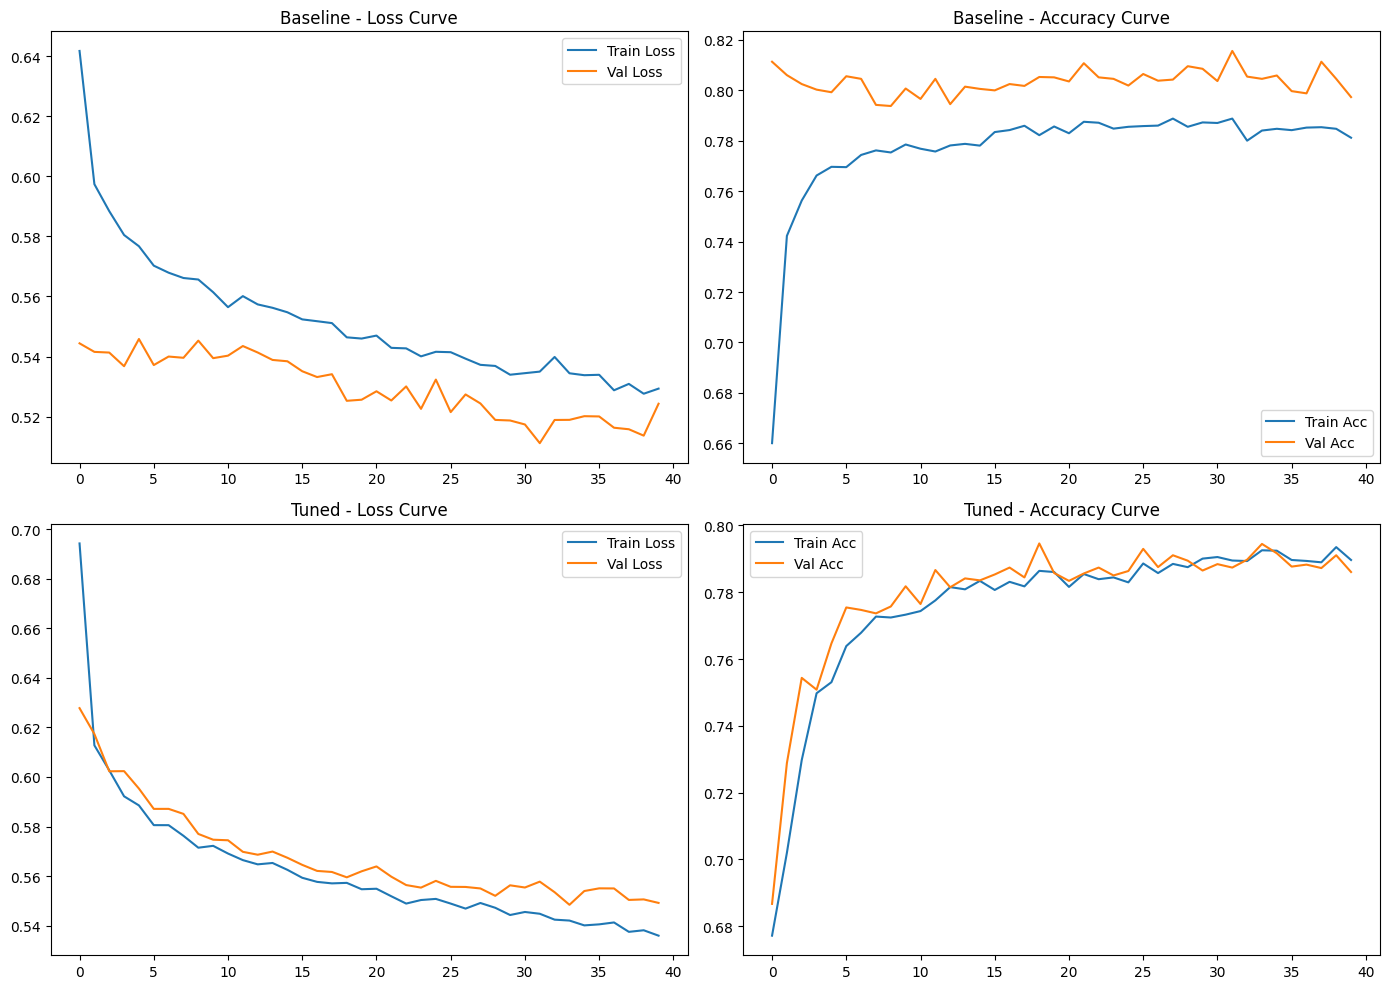

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Baseline Loss & Acc
ax[0, 0].plot(history_baseline.history['loss'], label='Train Loss')
ax[0, 0].plot(history_baseline.history['val_loss'], label='Val Loss')
ax[0, 0].set_title('Baseline - Loss Curve')
ax[0, 0].legend()

ax[0, 1].plot(history_baseline.history['accuracy'], label='Train Acc')
ax[0, 1].plot(history_baseline.history['val_accuracy'], label='Val Acc')
ax[0, 1].set_title('Baseline - Accuracy Curve')
ax[0, 1].legend()

# Tuned Loss & Acc
ax[1, 0].plot(history_tuned.history['loss'], label='Train Loss')
ax[1, 0].plot(history_tuned.history['val_loss'], label='Val Loss')
ax[1, 0].set_title('Tuned - Loss Curve')
ax[1, 0].legend()

ax[1, 1].plot(history_tuned.history['accuracy'], label='Train Acc')
ax[1, 1].plot(history_tuned.history['val_accuracy'], label='Val Acc')
ax[1, 1].set_title('Tuned - Accuracy Curve')
ax[1, 1].legend()

plt.tight_layout()
plt.show()

Fitur Unik 2: Threshold Tuning (Model Tuned)

In [14]:
val_probs = model_tuned.predict(X_val_scaled, verbose=0).flatten()
best_threshold = 0.5
best_f1 = 0

for t in np.arange(0.1, 0.9, 0.05):
    f1_t = precision_recall_fscore_support(
        (val_probs > t).astype(int), y_val, pos_label=1, average='binary', zero_division=0
    )[2]
    if f1_t > best_f1:
        best_f1 = f1_t
        best_threshold = t

print(f"\nThreshold Optimal untuk Model Tuned: {best_threshold:.2f}")


Threshold Optimal untuk Model Tuned: 0.70


Simpan Artefak untuk Deployment

In [15]:
model_tuned.save('mlp_bank_marketing.h5')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(X_train_encoded.columns.tolist(), 'kolom_fitur.pkl')
print("\nArtefak model Tuned ('mlp_bank_marketing.h5', 'scaler.pkl', 'kolom_fitur.pkl') berhasil disimpan!")


Artefak model Tuned ('mlp_bank_marketing.h5', 'scaler.pkl', 'kolom_fitur.pkl') berhasil disimpan!
